R² (Train): 0.984
R² (Test): 0.987
RMSE: Rs 219,263
R2 0.958
RMSE: Rs396,535
Linear Regression is better.


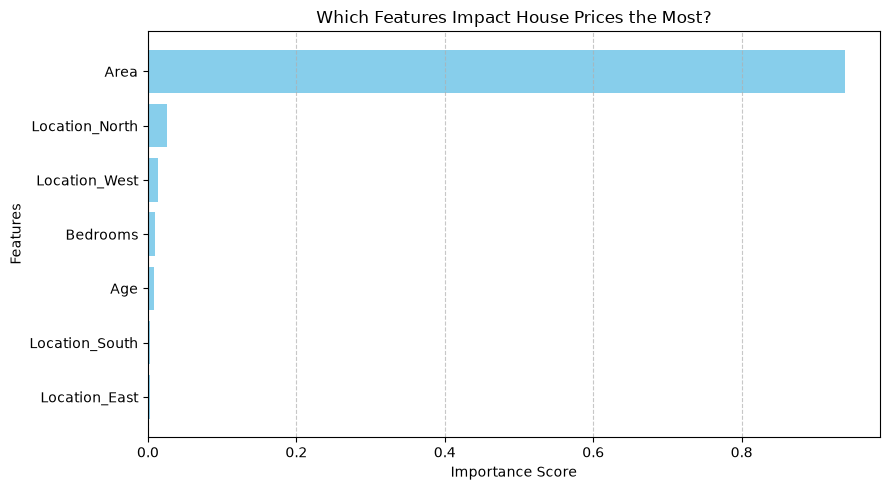

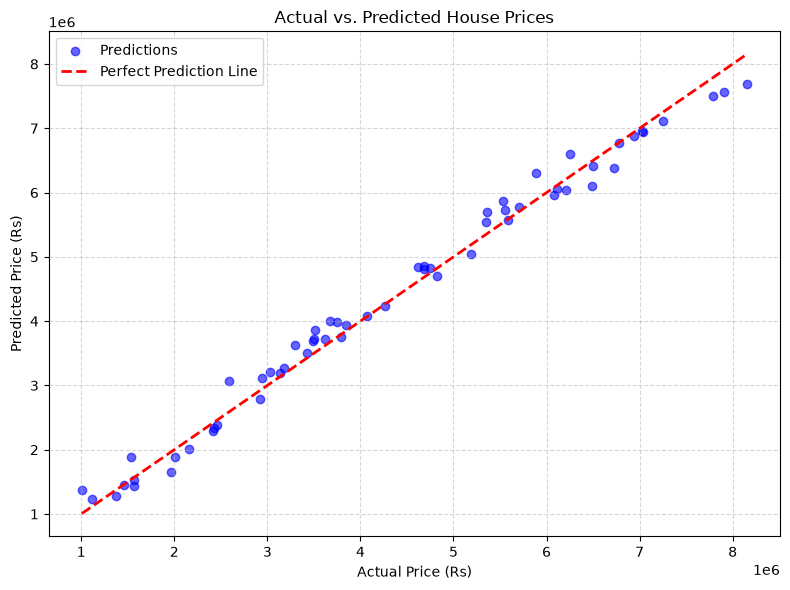

Predicted price: Rs 3,586,007


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

data = pd.read_csv('house_prices.csv')
regressor = LinearRegression()
rfr = RandomForestRegressor(n_estimators= 100, random_state= 42)
data = data.dropna()

data = pd.get_dummies(data, columns=['Location'])


y = data['Price']
features = data[['Area', 'Bedrooms', 'Age', 'Location_East', 'Location_North',
       'Location_South', 'Location_West']]
X = features.copy()
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2,random_state=0)
regressor.fit(X_train, y_train)
trainPredictions = regressor.predict(X_train)
validPredictions = regressor.predict(X_valid)

rfr.fit(X_train, y_train)
predictions= rfr.predict(X_valid)
r2_randomForestRegressor = r2_score(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

r2_train = r2_score(y_train, trainPredictions)
r2_test = r2_score(y_valid, validPredictions)

rmse_test = np.sqrt(mean_squared_error(y_valid, validPredictions))
print(f"R² (Train): {r2_train:.3f}")
print(f"R² (Test): {r2_test:.3f}")
print(f"RMSE: Rs {rmse_test:,.0f}")
print(f'R2 {r2_randomForestRegressor:.3f}')
print(f'RMSE: Rs{rmse:,.0f}')

if r2_randomForestRegressor > r2_test:
    print("Random Forest is better.")
    best_model = rfr
    best_predictions = predictions
else:
    print("Linear Regression is better.")
    best_model = regressor
    best_predictions = validPredictions

importance_df = (
    pd.DataFrame(
        {"Feature": X.columns, "Importance": rfr.feature_importances_}
    )
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(9, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="skyblue")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Which Features Impact House Prices the Most?")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 6))
plt.scatter(y_valid, best_predictions, alpha=0.6, color="blue", label="Predictions")

plt.plot(
    [y_valid.min(), y_valid.max()],
    [y_valid.min(), y_valid.max()],
    "r--",
    lw=2,
    label="Perfect Prediction Line",
)

plt.xlabel("Actual Price (Rs)")
plt.ylabel("Predicted Price (Rs)")
plt.title("Actual vs. Predicted House Prices")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

new_house = pd.DataFrame({
    'Area': [350],
    'Bedrooms': [4],
    'Age': [10],
    'Location_East': [0],
    'Location_North': [1],
    'Location_South': [0],
    'Location_West': [0]
})

predicted_price = best_model.predict(new_house)
print(f"Predicted price: Rs {predicted_price[0]:,.0f}")